# Predicting the Market Value of Attacking Players Using Linear Regression
### Does recorded high-level experience improve a performance-based estimate?

The starting point is a simple regression relating attacking output and player context to published market value. Its errors suggest a question: can prior top-five-league and Champions League experience help distinguish established players from those with similar current-season output?

The analysis keeps the initial **Baseline Model**, then tests an **Experience-Adjusted Model** on exactly the same players. Neither specification uses previous market value. The target is a Transfermarkt valuation, not a transfer fee.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'modelling.py').exists():
    raise FileNotFoundError('Open this notebook with the project folder as the working directory.')
from IPython.display import display, Markdown
import numpy as np
import pandas as pd
from modelling import load_data, fit_model, TARGET, BASE, EXPERIENCE
from evaluation import compare, metrics, subgroup_results, paired_bootstrap, temporal_checks, player_examples
from charts import accuracy_figure, robustness_figure, player_figure
from notebook_presentation import notebook_table, bootstrap_table
from sklearn.metrics import mean_absolute_error, median_absolute_error
pd.options.display.float_format = '{:,.2f}'.format
data = load_data()
training = data.loc[data.split.eq('train')].copy()
evaluation = data.loc[data.split.eq('test')].copy()

## 1. Sample and timing

The sample contains centre-forwards, second strikers, wingers and attacking midfielders in England, Spain, Germany, Italy and France. Eligibility requires age 18–36 and at least 900 domestic league minutes.

**Target rule:** take the latest recorded valuation available **as of 19 days after the last observed league match across the five leagues**. Retain it only if positive and **no more than 90 days old at that as-of date**. A newer zero or missing valuation is not replaced with an older positive one.

The 19-day offset defines the as-of cutoff. This offset matches the latest available 2025/26 valuation date (12 June 2026). The 90-day limit is a roughly quarterly freshness choice, not a statistically optimal threshold or a choice based on model accuracy. Coverage under 30- and 180-day alternatives is shown below.

Some valuations were published before the season finished, while inputs cover the full season. This is **contemporaneous estimation of published values around season end**, not a strict forecast of later valuation updates. Dates, valuation ages and a flag for valuations before performance end are retained in the data.

Positions come from the source profile snapshot, not historical position records. The 2025/26 French league has 305 recorded games, one short of a full schedule. Missing, nonpositive or stale valuations still exclude players.

Train: **2022/23–2024/25**. Development evaluation: **2025/26**. Players may appear in both earlier training seasons and the evaluation season; this does not test exclusively unseen players.

Source: [Transfermarkt datasets](https://github.com/dcaribou/transfermarkt-datasets). The prepared data and `data/source_notes.json` preserve the timing rules. `data/valuation_coverage.csv` records eligible, excluded and retained players by league, season and freshness limit.

In [2]:
display(Markdown("### Player sample by season and split"))
sample_by_season = data.groupby(["season", "split"]).agg(player_seasons=("player_id", "size"), median_value_eur=(TARGET, "median"))
display(notebook_table(sample_by_season))

display(Markdown("### Coverage by league and season"))
league_coverage = pd.crosstab(data.season, data.league).rename_axis(index="Season", columns=None).reset_index()
display(league_coverage.style.format(precision=2, thousands=",").hide(axis="index"))

display(Markdown("### Player counts under alternative freshness limits"))
coverage = pd.read_csv(ROOT / "data/valuation_coverage.csv")
freshness_counts = coverage.groupby(["season", "max_valuation_age_days"]).included_players.sum().unstack()
freshness_counts = freshness_counts.rename(columns=lambda days: f"{days}-day limit").rename_axis(index="Season", columns=None).reset_index()
display(freshness_counts.style.format(precision=2, thousands=",").hide(axis="index"))
display(Markdown("These are coverage checks, not alternative model scores. Historical source gaps remain: only 36 Ligue 1 players in 2022/23 and 41 Serie A players in 2024/25. Wider limits admit older targets and do not automatically improve validity."))

valuation_timing = data.groupby("season").agg(
    players=("player_id", "size"), median_valuation_age_days=("valuation_age_days", "median"),
    max_valuation_age_days=("valuation_age_days", "max"), valuations_before_performance_end=("valuation_before_performance_end", "sum"))
valuation_timing = valuation_timing.rename(columns={
    "players": "Players", "median_valuation_age_days": "Median valuation age (days)",
    "max_valuation_age_days": "Maximum valuation age (days)", "valuations_before_performance_end": "Valuations before season end"})
display(valuation_timing.rename_axis(index="Season", columns=None).reset_index().style.format(precision=2, thousands=",").hide(axis="index"))

### Player sample by season and split

Season,Sample,Player-seasons,Median published value (€m)
2022/23,Training,439,12.00
2023/24,Training,474,12.00
2024/25,Training,418,15.00
2025/26,Evaluation,489,15.00


### Coverage by league and season

Season,Bundesliga,La Liga,Ligue 1,Premier League,Serie A
2022/23,91,112,36,105,95
2023/24,91,105,84,107,87
2024/25,86,108,81,102,41
2025/26,92,113,81,111,92


### Player counts under alternative freshness limits

Season,30-day limit,90-day limit,180-day limit
2022/23,406,439,439
2023/24,474,474,474
2024/25,378,418,459
2025/26,489,489,489


These are coverage checks, not alternative model scores. Historical source gaps remain: only 36 Ligue 1 players in 2022/23 and 41 Serie A players in 2024/25. Wider limits admit older targets and do not automatically improve validity.

Season,Players,Median valuation age (days),Maximum valuation age (days),Valuations before season end
2022/23,439,8.00,88.00,33
2023/24,474,18.00,25.00,200
2024/25,418,10.00,85.00,40
2025/26,489,11.00,22.00,1


## 2. Initial specification: Baseline Model

Ordinary least squares predicts **log(value in euros)** from age centred at 25, centred age squared, log(minutes / 1,800), goals per 90, assists per 90, league and attacking position. Age squared allows a curved age relationship; minutes are logged to reduce the influence of large exposure differences.

Categorical league and position variables are dummy-encoded, using Bundesliga and Attacking Midfield as the reference categories. Categories are learned only from training and sorted alphabetically with the first category omitted. An intercept is fitted. Predictions are directly exponentiated without a smearing correction or cap, preserving the existing specification. This does not directly optimise error measured in euros and does not produce an unbiased conditional mean forecast.

The shared module uses `sklearn.linear_model.LinearRegression`. Explicit feature construction makes the transformations and reference groups visible.

In [3]:
model = fit_model(training, 'model')
model_predictions = model.predict(evaluation)
print(f'Baseline Model MAE: €{mean_absolute_error(evaluation[TARGET], model_predictions)/1e6:.2f}m')
print(f'Baseline Model median absolute error: €{median_absolute_error(evaluation[TARGET], model_predictions)/1e6:.2f}m')

Baseline Model MAE: €10.39m
Baseline Model median absolute error: €4.53m


## 3. What the initial errors suggest

Several established, high-value players are substantially underestimated. Mbappé is a useful motivating example, although one prominent player cannot establish a general failure. The table includes every evaluation player with published value of at least €100m rather than selecting only favourable cases.

In [4]:
initial_errors = evaluation[['name', TARGET]].copy()
initial_errors['model_prediction_eur'] = model_predictions
initial_errors['signed_error_eur'] = model_predictions - evaluation[TARGET]
display(notebook_table(initial_errors.loc[initial_errors[TARGET].ge(100e6)].sort_values(TARGET, ascending=False)))

Player,Published value (€m),Baseline Model prediction (€m),Prediction error (€m)
Erling Haaland,200.00,153.77,-46.23
Lamine Yamal,200.00,127.93,-72.07
Kylian Mbappé,180.00,49.05,-130.95
Michael Olise,150.00,152.74,2.74
Vinicius Junior,140.00,36.23,-103.77
Khvicha Kvaratskhelia,140.00,19.83,-120.17
Jude Bellingham,130.00,21.44,-108.56
Désiré Doué,120.00,32.45,-87.55
Bukayo Saka,110.00,45.23,-64.77
Dominik Szoboszlai,100.00,40.68,-59.32


## 4. Hypothesis and extension: Experience-Adjusted Model

Current-season production may not capture established high-level experience. Add two objective proxies: prior top-five-league minutes and prior Champions League minutes, each transformed as **log(1 + prior minutes)**. This gives more weight to the first increments of experience than equally sized increments late in a career.

Both totals stop before the season begins. Champions League qualifiers are excluded. Recorded history starts in 2012, so these are observed-history totals rather than guaranteed complete careers. Zero means no qualifying minutes in the records, not proof of no experience.

Only these two columns are added. The training observations, outcome, other features and evaluation players remain unchanged. Experience may reflect selection and opportunity as well as reputation; these coefficients are associations, not causal effects.

Model,Evaluation players,MAE (€m),Median absolute error (€m)
Baseline Model,489,10.39,4.53
Experience-Adjusted Model,489,8.70,3.96


MAE reduction: 16.3%


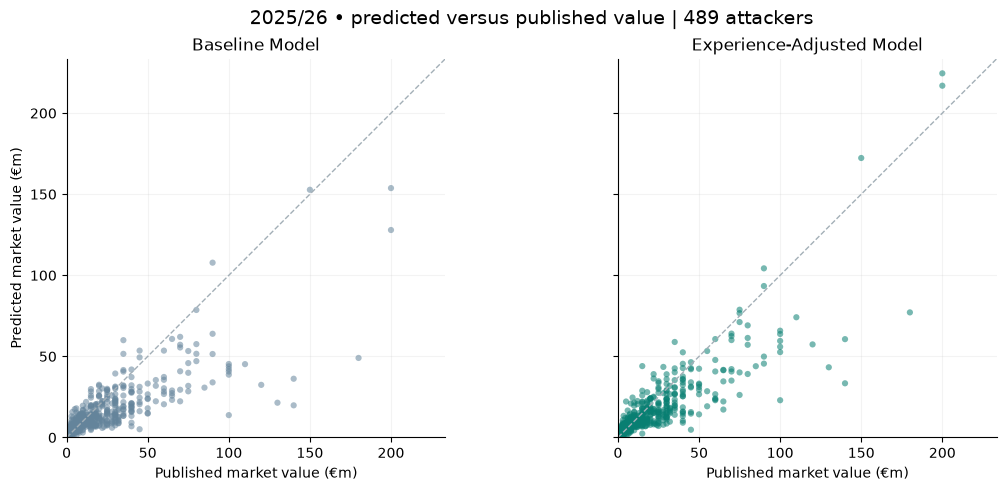

In [5]:
extended_model = fit_model(training, 'extended_model')
assert model.training_rows == extended_model.training_rows == len(training)
assert not evaluation.player_id.duplicated().any()
assert list(extended_model.design(training).columns[:-2]) == list(model.design(training).columns)
predictions = compare(evaluation, model, extended_model)
scores = metrics(predictions)
display(notebook_table(scores))
reduction = 100*(1-scores.loc['extended_model', 'MAE_EUR']/scores.loc['model', 'MAE_EUR'])
print(f'MAE reduction: {reduction:.1f}%')
display(accuracy_figure(predictions))

## 5. Player-level comparisons

Mbappé is retained as the motivating case. To show both sides of the result, the other examples are selected mechanically: the three largest reductions and the three largest increases in absolute error. Positive error reduction means the Experience-Adjusted Model is closer to the published value.

Mbappé remains materially underestimated. Olise, Igor Thiago and João Pedro illustrate setbacks: the extension increases their absolute errors. Olise becomes more overestimated, while Igor Thiago and João Pedro become more underestimated. Better aggregate accuracy does not mean better predictions for every player.

Player,Published value (€m),Baseline Model prediction (€m),Experience-Adjusted Model prediction (€m),Reduction in absolute error (€m)
Kylian Mbappé,180.00,49.05,77.14,28.09
Lamine Yamal,200.00,127.93,224.53,47.55
Kenan Yıldız,75.00,39.89,71.17,31.27
Erling Haaland,200.00,153.77,216.91,29.32
Michael Olise,150.00,152.74,172.33,-19.59
Igor Thiago,65.00,60.76,41.45,-19.31
João Pedro,80.00,78.63,61.38,-17.25


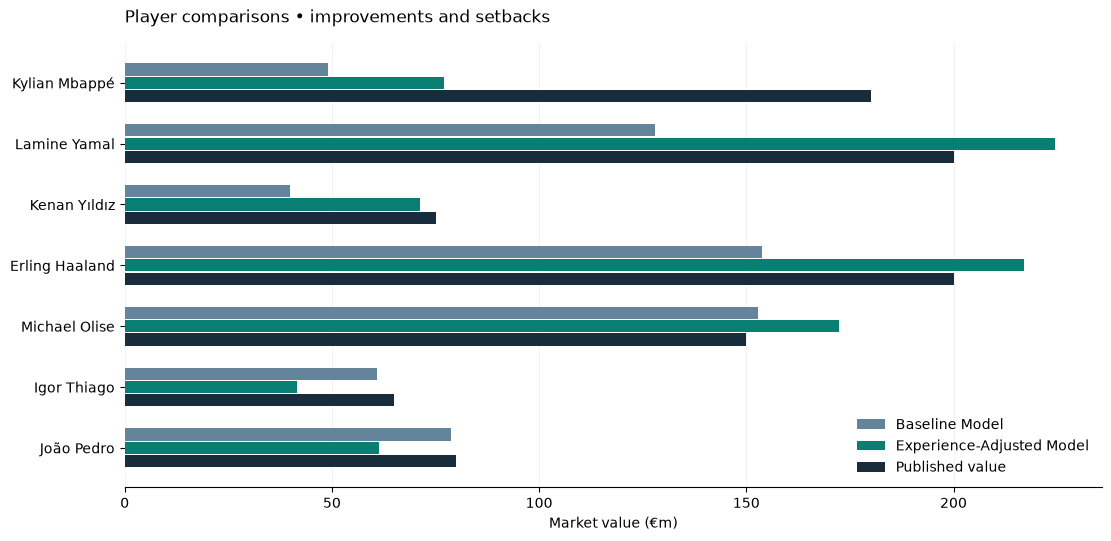

In [6]:
examples = player_examples(predictions)
display(notebook_table(examples[['name', TARGET, 'model_prediction_eur', 'extended_model_prediction_eur', 'error_reduction_eur']]))
display(player_figure(examples))

## 6. Robustness: sample composition and season choice

The following checks examine sample composition and season choice without changing either main model.

### Subgroup robustness

Removing the ten highest published values and comparing within each league checks whether the benefit depends only on stars or a particular competition.

Subgroup,Evaluation players,Baseline Model MAE (€m),Experience-Adjusted Model MAE (€m)
All players,489,10.39,8.70
Exclude 10 highest published values,479,8.95,7.66
Bundesliga,92,6.37,6.46
La Liga,113,11.47,9.36
Ligue 1,81,9.79,7.68
Premier League,111,14.95,12.93
Serie A,92,8.14,5.90


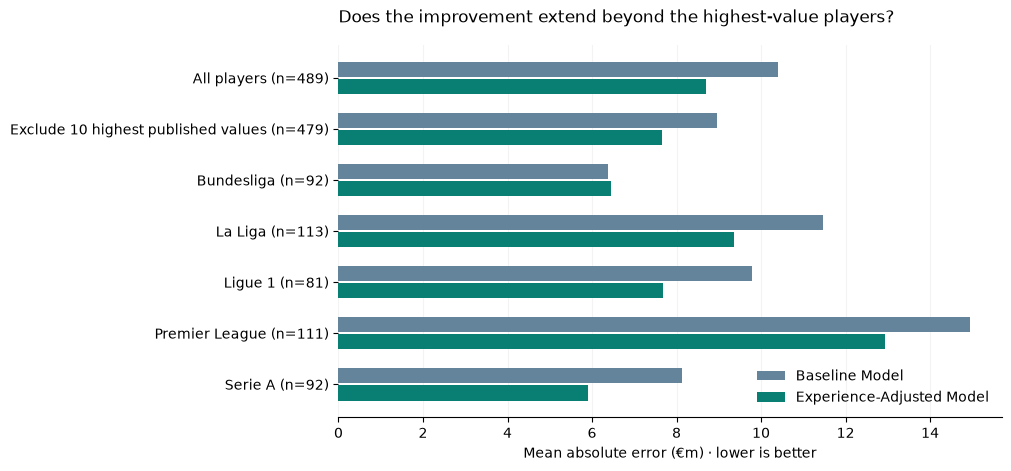

In [7]:
groups = subgroup_results(predictions)
display(notebook_table(groups))
display(robustness_figure(groups))

### Paired bootstrap result

Resampling evaluation players in pairs, with both fitted models held fixed, shows how variable the difference in MAE is within this sample.

The bootstrap uses 2,000 draws and a fixed seed of 27. Its interval is conditional on the fitted models and this selected sample. It does not reflect training uncertainty, shared league effects or future-season drift, and is not an interval for an individual player's value.

In [8]:
bootstrap = paired_bootstrap(predictions)
display(bootstrap_table(bootstrap))

MAE reduction (€m),95% bootstrap interval (€m),Players improved (%)
1.70,1.11 to 2.33,57.7


### Earlier-season checks

Repeat both specifications using only earlier seasons for training. These checks compare subsequent seasons, but individual targets may predate the end of their performance season under the as-of rule. Uneven historical league coverage remains a limitation.

In [9]:
display(notebook_table(temporal_checks(data)))

Training seasons,Evaluation season,Training player-seasons,Evaluation players,Baseline Model MAE (€m),Experience-Adjusted Model MAE (€m)
2022/23,2023/24,439,474,10.47,9.55
"2022/23, 2023/24",2024/25,913,418,10.66,9.00
"2022/23, 2023/24, 2024/25",2025/26,"1,331",489,10.39,8.70


The improvement survives removing the ten highest-value players and appears in both earlier-season comparisons. It is not universal: Bundesliga MAE is slightly worse, and about 58% of individual players improve. The paired bootstrap interval for the MAE reduction is roughly €1.11m–€2.33m.

These checks support the usefulness of recorded experience in this dataset. They do not establish that these inputs measure reputation directly or will always improve a new season. Differences in league coverage and target timing limit comparisons across seasons.

## 7. Limits and the next test

The 2025/26 outcomes were excluded from coefficient fitting, but their errors motivated the extension. These results are a **development evaluation**, not a pristine final test. Earlier-season checks are retrospective too. The next decisive check is a genuinely untouched later season with both the specification and valuation rule fixed in advance.

The target is the latest sufficiently recent published value at the as-of cutoff. Some valuations predate the final performance observations, so this is not a strict future-update forecast. The 90-day freshness rule reduces stale targets but does not eliminate valuation-update selection or missing-source bias.

Contract length, wages, injuries, international performance and other valuation drivers are absent. The target itself is an estimate, not a transfer fee. Selection by minutes, incomplete historical coverage and retrospective position labels limit generalisation. Extrapolation warnings identify inputs beyond training ranges; they do not quantify prediction uncertainty.

## 8. Explore a player

From a terminal in this project folder, run `py -m streamlit run app.py`. The app provides searchable players, both model estimates, dated published values, hypothetical performance inputs and evaluation comparisons. Scenario changes affect the selected profile only; accuracy plots and reported evaluation scores remain fixed.
